# Pipeline Operational Analysis

This notebook extracts operational findings from the pipeline JSON files to support the article's Model Selection and Development Process sections. It answers:

1. **Model preference**: Which translation model was chosen as base most frequently by the reviewer?
2. **Critique scores**: How did each model score in the reviewer's analysis?
3. **Cost breakdown**: How much did each stage cost per dataset?
4. **Content filters**: How many entries triggered content filters, and which models?
5. **Evaluation scores**: Distribution of quality scores across datasets
6. **Truncation**: How many entries had programmatic adjustments?
7. **Processing time**: Approximate throughput per dataset

In [1]:
import json
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (14, 5)})
pd.set_option('display.float_format', '{:,.2f}'.format)

# Load pipeline JSONs
PIPELINE_FILES = {
    'WikiText': Path('../output/wikitext/wikitext-103-raw.wiki.train.selected_1000_pipeline_260620_235838.json'),
    'FEVER':    Path('../output/FEVER/fever_selected_pipeline_260712_212751.json'),
    'Europarl': Path('../output/Europarl/selected_pipeline_260710_084528.json'),
}

pipelines = {}
for name, path in PIPELINE_FILES.items():
    with open(path, 'r', encoding='utf-8') as f:
        pipelines[name] = json.load(f)
    n = len(pipelines[name]['pipeline'])
    print(f"  {name}: {n:,} entries loaded")

DATASETS = list(pipelines.keys())
print("\nAll pipeline files loaded.")

  WikiText: 1,000 entries loaded
  FEVER: 9,998 entries loaded
  Europarl: 1,005 entries loaded

All pipeline files loaded.


---
## 1. Cost Breakdown per Dataset and Stage

In [2]:
rows = []
for ds in DATASETS:
    s = pipelines[ds]['summary']
    cost = s['total_cost_usd']
    tokens = s['total_tokens']
    
    # Stage 1 translation costs per model
    s1_costs = cost.get('stage_1_translation', {})
    s1_total = sum(s1_costs.values())
    
    rows.append({
        'Dataset': ds,
        'Entries': s['articles_processed'],
        'Stage 3 (Translation)': f"${s1_total:,.2f}",
        'Stage 4 (Review)': f"${cost.get('stage_2_review', 0):,.2f}",
        'Stage 5 (Evaluation)': f"${cost.get('stage_3_evaluation', 0):,.2f}",
        'Stage 6 (Metadata)': f"${cost.get('metadata', 0):,.2f}",
        'Total': f"${cost.get('total', 0):,.2f}",
        'Cost/Entry': f"${cost.get('total', 0) / s['articles_processed']:,.4f}",
        'Total Tokens': f"{tokens.get('total_tokens', 0):,}",
    })

df_cost = pd.DataFrame(rows)
display(df_cost)

# Stage 1 cost breakdown by model
print("\n--- Stage 3 Translation cost by model ---")
for ds in DATASETS:
    cost = pipelines[ds]['summary']['total_cost_usd']
    s1 = cost.get('stage_1_translation', {})
    print(f"\n  {ds}:")
    for model, c in sorted(s1.items()):
        short = model.split(':')[-1] if ':' in model else model
        print(f"    {short:<35} ${c:,.2f}")

,Dataset,Entries,Stage 3 (Translation),Stage 4 (Review),Stage 5 (Evaluation),Stage 6 (Metadata),Total,Cost/Entry,Total Tokens
0,WikiText,1000,$20.00,$76.87,$3.76,$3.91,$104.54,$0.1045,"70,917,901"
1,FEVER,9998,$14.45,$114.73,$6.39,$6.60,$142.17,$0.0142,"83,138,788"
2,Europarl,1005,$42.81,$156.44,$6.88,$1.05,$207.18,$0.2062,"130,419,945"



--- Stage 3 Translation cost by model ---

  WikiText:
    dataset-frontierscience-gpt41mini   $9.01
    dataset-frontierscience-mistral-large $10.98
    9b                                  $0.00

  FEVER:
    dataset-frontierscience-gpt41mini   $6.76
    dataset-frontierscience-mistral-large $7.69
    9b                                  $0.00

  Europarl:
    dataset-frontierscience-gpt41mini   $20.07
    dataset-frontierscience-mistral-large $22.73
    9b                                  $0.00


---
## 2. Reviewer Critique: Model Scores and Preferences

Which model scored highest in the reviewer's analysis? Which was chosen as the base for the consensus translation?

In [3]:
# Extract critique scores per model per dataset
for ds in DATASETS:
    print(f"\n{'='*60}")
    print(f"  {ds}")
    print(f"{'='*60}")
    
    model_scores = defaultdict(list)
    highest_count = Counter()
    entries_with_critique = 0
    entries_without_critique = 0
    
    for entry in pipelines[ds]['pipeline']:
        review = entry.get('review')
        if not review or not review.get('critique'):
            entries_without_critique += 1
            continue
        
        critique = review['critique']
        if isinstance(critique, dict) and 'candidates_analysis' in critique:
            entries_with_critique += 1
            best_score = -1
            best_model = None
            
            for ca in critique['candidates_analysis']:
                model = ca.get('model', '?')
                score = ca.get('score')
                if isinstance(score, (int, float)):
                    # Shorten model name
                    short = model.split(':')[-1] if ':' in model else model
                    model_scores[short].append(score)
                    if score > best_score:
                        best_score = score
                        best_model = short
            
            if best_model:
                highest_count[best_model] += 1
        else:
            entries_without_critique += 1
    
    print(f"  Entries with structured critique: {entries_with_critique:,}")
    print(f"  Entries without critique: {entries_without_critique:,}")
    
    # Score statistics per model
    print(f"\n  --- Critique Scores per Model ---")
    print(f"  {'Model':<35} {'Mean':>6} {'Median':>7} {'Std':>6} {'Min':>5} {'Max':>5} {'N':>6}")
    print(f"  {'-'*72}")
    for model in sorted(model_scores.keys()):
        scores = model_scores[model]
        arr = np.array(scores)
        print(f"  {model:<35} {arr.mean():>6.1f} {np.median(arr):>7.1f} {arr.std():>6.1f} {arr.min():>5.0f} {arr.max():>5.0f} {len(arr):>6,}")
    
    # Which model "wins" most often
    print(f"\n  --- Highest Score Count (chosen as base) ---")
    total = sum(highest_count.values())
    for model, count in highest_count.most_common():
        pct = count / total * 100 if total > 0 else 0
        print(f"  {model:<35} {count:>6,} ({pct:>5.1f}%)")


  WikiText
  Entries with structured critique: 988
  Entries without critique: 12

  --- Critique Scores per Model ---
  Model                                 Mean  Median    Std   Min   Max      N
  ------------------------------------------------------------------------
  9b                                    84.8    85.0    5.5    40    95    988
  dataset-frontierscience-gpt41mini     85.6    88.0   10.4    10    93    988
  dataset-frontierscience-mistral-large   81.2    90.0   19.7    10    95    974

  --- Highest Score Count (chosen as base) ---
  dataset-frontierscience-mistral-large    615 ( 62.2%)
  dataset-frontierscience-gpt41mini      201 ( 20.3%)
  9b                                     172 ( 17.4%)

  FEVER
  Entries with structured critique: 9,807
  Entries without critique: 191

  --- Critique Scores per Model ---
  Model                                 Mean  Median    Std   Min   Max      N
  ------------------------------------------------------------------------
 

---
## 3. Evaluation Scores Distribution

How did the final translations score on clarity, fidelity, completeness, fluency, and overall?

,Dataset,Clarity (mean),Clarity (median),Clarity (std),Fidelity (mean),Fidelity (median),Fidelity (std),Completeness (mean),Completeness (median),Completeness (std),Fluency (mean),Fluency (median),Fluency (std),Overall Score (mean),Overall Score (median),Overall Score (std),N
0,WikiText,97.70,98.00,1.00,97.60,98.00,1.30,99.80,100.00,1.60,97.50,98.00,1.00,95.90,96.00,2.00,995
1,FEVER,96.90,98.00,1.50,96.70,98.00,2.20,99.70,100.00,2.40,96.70,98.00,1.70,95.10,95.00,2.50,9994
2,Europarl,97.70,98.00,0.90,98.10,98.00,0.90,100.00,100.00,0.00,97.40,98.00,1.00,97.00,98.00,1.60,1003


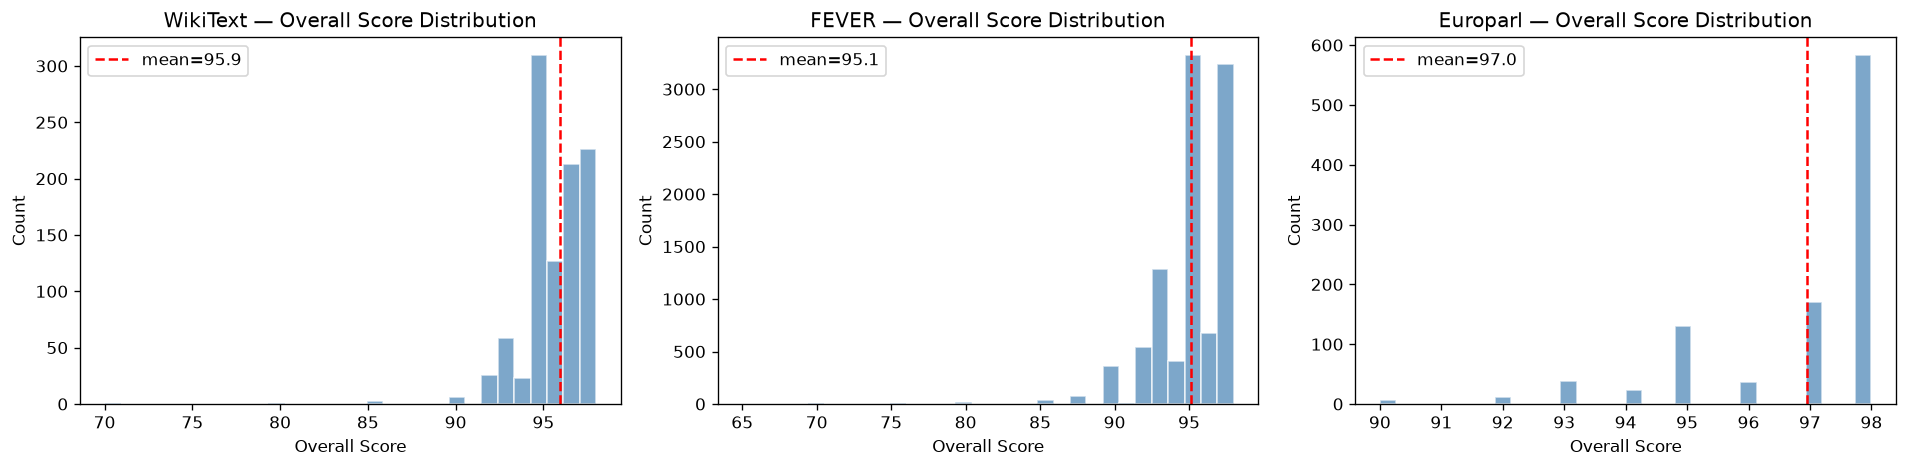


--- Entries by overall score range ---
  Range             WikiText      FEVER   Europarl
  -----------------------------------------------
  95-100                 876      7,244        923
  90-94                  114      2,602         80
  85-89                    3        111          0
  80-84                    1         21          0
  70-79                    1         15          0
  <70                      0          1          0


In [4]:
dimensions = ['clarity', 'fidelity', 'completeness', 'fluency', 'overall_score']

rows = []
for ds in DATASETS:
    scores = defaultdict(list)
    for entry in pipelines[ds]['pipeline']:
        ev = entry.get('evaluation')
        if ev and isinstance(ev, dict):
            for dim in dimensions:
                val = ev.get(dim)
                if isinstance(val, (int, float)):
                    scores[dim].append(val)
    
    row = {'Dataset': ds}
    for dim in dimensions:
        arr = np.array(scores[dim]) if scores[dim] else np.array([0])
        label = dim.replace('_', ' ').title()
        row[f'{label} (mean)'] = round(arr.mean(), 1)
        row[f'{label} (median)'] = round(float(np.median(arr)), 1)
        row[f'{label} (std)'] = round(arr.std(), 1)
    row['N'] = len(scores['overall_score'])
    rows.append(row)

df_eval = pd.DataFrame(rows)
display(df_eval)

# Score distribution histograms
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, ds in enumerate(DATASETS):
    scores = []
    for entry in pipelines[ds]['pipeline']:
        ev = entry.get('evaluation')
        if ev and isinstance(ev, dict) and 'overall_score' in ev:
            scores.append(ev['overall_score'])
    axes[i].hist(scores, bins=30, color='steelblue', alpha=0.7, edgecolor='white')
    axes[i].set_title(f'{ds} — Overall Score Distribution')
    axes[i].set_xlabel('Overall Score')
    axes[i].set_ylabel('Count')
    axes[i].axvline(np.mean(scores), color='red', linestyle='--', label=f'mean={np.mean(scores):.1f}')
    axes[i].legend()
plt.tight_layout()
plt.show()

# Entries by score range
print("\n--- Entries by overall score range ---")
print(f"  {'Range':<15} {'WikiText':>10} {'FEVER':>10} {'Europarl':>10}")
print(f"  {'-'*47}")
for lo, hi, label in [(95,101,'95-100'), (90,95,'90-94'), (85,90,'85-89'), 
                       (80,85,'80-84'), (70,80,'70-79'), (0,70,'<70')]:
    vals = []
    for ds in DATASETS:
        count = sum(1 for e in pipelines[ds]['pipeline'] 
                    if e.get('evaluation') and isinstance(e['evaluation'], dict)
                    and lo <= e['evaluation'].get('overall_score', 0) < hi)
        vals.append(count)
    print(f"  {label:<15} {vals[0]:>10,} {vals[1]:>10,} {vals[2]:>10,}")

---
## 4. Content Filters and Errors

How many entries triggered content filters? Which models? How many entries had no evaluation?

In [5]:
for ds in DATASETS:
    print(f"\n{'='*60}")
    print(f"  {ds}")
    print(f"{'='*60}")
    
    total = len(pipelines[ds]['pipeline'])
    cf_count = 0
    cf_models = Counter()
    no_eval = 0
    no_review = 0
    no_candidates = 0
    candidates_missing_model = 0
    
    for entry in pipelines[ds]['pipeline']:
        # Content filters
        cf = entry.get('content_filter')
        if cf:
            cf_count += 1
            for model in cf:
                short = model.split(':')[-1] if ':' in model else model
                cf_models[short] += 1
        
        # Missing stages
        if not entry.get('evaluation') or entry.get('evaluation') is None:
            no_eval += 1
        if not entry.get('review') or entry.get('review') is None:
            no_review += 1
        
        # Check candidates count
        cands = entry.get('candidates', [])
        if len(cands) < 3:
            candidates_missing_model += 1
        if len(cands) == 0:
            no_candidates += 1
    
    print(f"  Total entries: {total:,}")
    print(f"  Content filter triggers: {cf_count} ({cf_count/total*100:.2f}%)")
    if cf_models:
        for model, count in cf_models.most_common():
            print(f"    {model}: {count}")
    print(f"  Entries without evaluation: {no_eval}")
    print(f"  Entries without review: {no_review}")
    print(f"  Entries with < 3 candidates: {candidates_missing_model}")
    print(f"  Entries with 0 candidates: {no_candidates}")


  WikiText
  Total entries: 1,000
  Content filter triggers: 0 (0.00%)
  Entries without evaluation: 5
  Entries without review: 7
  Entries with < 3 candidates: 19
  Entries with 0 candidates: 0

  FEVER
  Total entries: 9,998
  Content filter triggers: 0 (0.00%)
  Entries without evaluation: 4
  Entries without review: 8
  Entries with < 3 candidates: 26
  Entries with 0 candidates: 0

  Europarl
  Total entries: 1,005
  Content filter triggers: 0 (0.00%)
  Entries without evaluation: 2
  Entries without review: 3
  Entries with < 3 candidates: 27
  Entries with 0 candidates: 0


---
## 5. Programmatic Truncation Adjustments

How many entries had their completeness score overridden by the programmatic check?

In [6]:
for ds in DATASETS:
    total = len(pipelines[ds]['pipeline'])
    adjusted = 0
    char_ratios = []
    adjusted_details = []
    
    for entry in pipelines[ds]['pipeline']:
        ev = entry.get('evaluation')
        if ev and isinstance(ev, dict):
            cr = ev.get('char_ratio')
            if isinstance(cr, (int, float)):
                char_ratios.append(cr)
            
            if 'programmatic_adjustment' in ev:
                adjusted += 1
                adj = ev['programmatic_adjustment']
                adjusted_details.append({
                    'id': entry.get('article_id', '?'),
                    'char_ratio': cr,
                    'llm_completeness': adj.get('llm_completeness', '?'),
                    'adjusted_completeness': adj.get('adjusted_completeness', '?'),
                    'llm_overall': adj.get('llm_overall', '?'),
                    'adjusted_overall': adj.get('adjusted_overall', '?'),
                })
    
    arr = np.array(char_ratios) if char_ratios else np.array([0])
    print(f"\n{ds}:")
    print(f"  Entries with evaluation: {len(char_ratios):,}")
    print(f"  Programmatic adjustments: {adjusted} ({adjusted/total*100:.2f}%)")
    print(f"  Char ratio: mean={arr.mean():.3f}, median={np.median(arr):.3f}, min={arr.min():.3f}, max={arr.max():.3f}")
    print(f"  Entries with char_ratio < 0.85: {sum(1 for r in char_ratios if r < 0.85)}")
    print(f"  Entries with char_ratio < 1.0:  {sum(1 for r in char_ratios if r < 1.0)}")
    
    if adjusted_details:
        print(f"\n  Adjustment details (first 10):")
        for d in adjusted_details[:10]:
            print(f"    id={d['id']}, ratio={d['char_ratio']}, "
                  f"LLM={d['llm_completeness']}->{d['adjusted_completeness']}, "
                  f"overall={d['llm_overall']}->{d['adjusted_overall']}")


WikiText:
  Entries with evaluation: 995
  Programmatic adjustments: 0 (0.00%)
  Char ratio: mean=1.044, median=1.044, min=0.794, max=1.182
  Entries with char_ratio < 0.85: 1
  Entries with char_ratio < 1.0:  90

FEVER:
  Entries with evaluation: 9,994
  Programmatic adjustments: 0 (0.00%)
  Char ratio: mean=1.091, median=1.091, min=0.568, max=1.646
  Entries with char_ratio < 0.85: 31
  Entries with char_ratio < 1.0:  640

Europarl:
  Entries with evaluation: 1,003
  Programmatic adjustments: 0 (0.00%)
  Char ratio: mean=1.053, median=1.054, min=0.939, max=1.182
  Entries with char_ratio < 0.85: 0
  Entries with char_ratio < 1.0:  15


---
## 6. Inter-Model Agreement

How similar are the translations produced by the 3 models? Measured by character length correlation and Jaccard similarity on word sets.

In [7]:
import re as re_mod

def tokenize(text):
    return set(re_mod.findall(r'\b\w+\b', text.lower()))

def jaccard(a, b):
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b) if (a | b) else 0

for ds in DATASETS:
    print(f"\n{'='*60}")
    print(f"  {ds}")
    print(f"{'='*60}")
    
    # Collect per-entry data
    model_names = set()
    pairwise_jaccard = defaultdict(list)
    pairwise_len_diff = defaultdict(list)
    model_char_counts = defaultdict(list)
    entries_with_3 = 0
    
    # Sample for Jaccard (expensive on full FEVER)
    entries = pipelines[ds]['pipeline']
    sample_indices = list(range(len(entries)))
    if len(entries) > 1000:
        rng = np.random.default_rng(42)
        sample_indices = sorted(rng.choice(len(entries), 1000, replace=False))
    
    for idx in sample_indices:
        entry = entries[idx]
        cands = entry.get('candidates', [])
        if len(cands) < 2:
            continue
        if len(cands) >= 3:
            entries_with_3 += 1
        
        # Get texts and models
        texts = {}
        for c in cands:
            model = c.get('model', '?')
            short = model.split(':')[-1] if ':' in model else model
            model_names.add(short)
            texts[short] = c.get('text', '')
            model_char_counts[short].append(len(c.get('text', '')))
        
        # Pairwise comparisons
        models = sorted(texts.keys())
        for i in range(len(models)):
            for j in range(i+1, len(models)):
                pair = f"{models[i]} vs {models[j]}"
                # Jaccard on word sets
                words_a = tokenize(texts[models[i]])
                words_b = tokenize(texts[models[j]])
                pairwise_jaccard[pair].append(jaccard(words_a, words_b))
                # Length difference ratio
                la, lb = len(texts[models[i]]), len(texts[models[j]])
                if max(la, lb) > 0:
                    pairwise_len_diff[pair].append(min(la, lb) / max(la, lb))
    
    print(f"  Entries analyzed: {len(sample_indices):,} (3-candidate: {entries_with_3:,})")
    
    # Average char counts per model
    print(f"\n  --- Average output length per model ---")
    for model in sorted(model_char_counts.keys()):
        arr = np.array(model_char_counts[model])
        print(f"  {model:<35} mean={arr.mean():,.0f} chars, std={arr.std():,.0f}")
    
    # Pairwise similarity
    print(f"\n  --- Pairwise similarity ---")
    print(f"  {'Pair':<50} {'Jaccard':>8} {'Len Ratio':>10}")
    print(f"  {'-'*70}")
    for pair in sorted(pairwise_jaccard.keys()):
        j_arr = np.array(pairwise_jaccard[pair])
        l_arr = np.array(pairwise_len_diff[pair])
        print(f"  {pair:<50} {j_arr.mean():>8.3f} {l_arr.mean():>10.3f}")


  WikiText
  Entries analyzed: 1,000 (3-candidate: 981)

  --- Average output length per model ---
  9b                                  mean=18,802 chars, std=11,735
  dataset-frontierscience-gpt41mini   mean=18,236 chars, std=11,452
  dataset-frontierscience-mistral-large mean=17,926 chars, std=11,196

  --- Pairwise similarity ---
  Pair                                                Jaccard  Len Ratio
  ----------------------------------------------------------------------
  9b vs dataset-frontierscience-gpt41mini               0.716      0.966
  9b vs dataset-frontierscience-mistral-large           0.582      0.956
  dataset-frontierscience-gpt41mini vs dataset-frontierscience-mistral-large    0.627      0.965

  FEVER
  Entries analyzed: 1,000 (3-candidate: 995)

  --- Average output length per model ---
  9b                                  mean=1,138 chars, std=632
  dataset-frontierscience-gpt41mini   mean=1,125 chars, std=621
  dataset-frontierscience-mistral-large mean=1,13

---
## 7. Processing Time and Throughput

Approximate processing duration based on timestamps in the pipeline JSON.

In [8]:
from datetime import datetime

for ds in DATASETS:
    entries = pipelines[ds]['pipeline']
    
    # Collect all timestamps from candidates and reviews
    timestamps = []
    for entry in entries:
        for c in entry.get('candidates', []):
            ts = c.get('translated_at', '')
            if ts:
                timestamps.append(ts)
        review = entry.get('review')
        if review and review.get('reviewed_at'):
            timestamps.append(review['reviewed_at'])
        ev = entry.get('evaluation')
        if ev and isinstance(ev, dict) and ev.get('evaluated_at'):
            timestamps.append(ev['evaluated_at'])
    
    if timestamps:
        # Parse timestamps (handle different formats)
        parsed = []
        for ts in timestamps:
            try:
                if '.' in ts:
                    parsed.append(datetime.fromisoformat(ts))
                else:
                    parsed.append(datetime.fromisoformat(ts))
            except:
                pass
        
        if parsed:
            first = min(parsed)
            last = max(parsed)
            duration = last - first
            hours = duration.total_seconds() / 3600
            
            n = len(entries)
            entries_per_hour = n / hours if hours > 0 else 0
            
            print(f"\n{ds}:")
            print(f"  First timestamp: {first}")
            print(f"  Last timestamp:  {last}")
            print(f"  Duration: {duration} ({hours:.1f} hours)")
            print(f"  Entries: {n:,}")
            print(f"  Throughput: {entries_per_hour:.1f} entries/hour")
            print(f"  Avg time/entry: {duration.total_seconds()/n:.1f} seconds")
        else:
            print(f"\n{ds}: Could not parse timestamps")
    else:
        print(f"\n{ds}: No timestamps found")


WikiText:
  First timestamp: 2026-06-15 23:10:22.865619
  Last timestamp:  2026-06-20 23:58:32.819696
  Duration: 5 days, 0:48:09.954077 (120.8 hours)
  Entries: 1,000
  Throughput: 8.3 entries/hour
  Avg time/entry: 434.9 seconds

FEVER:
  First timestamp: 2026-07-01 19:08:50.667038
  Last timestamp:  2026-07-12 21:27:38.813551
  Duration: 11 days, 2:18:48.146513 (266.3 hours)
  Entries: 9,998
  Throughput: 37.5 entries/hour
  Avg time/entry: 95.9 seconds

Europarl:
  First timestamp: 2026-06-30 21:12:08.535280
  Last timestamp:  2026-07-10 08:45:18.950799
  Duration: 9 days, 11:33:10.415519 (227.6 hours)
  Entries: 1,005
  Throughput: 4.4 entries/hour
  Avg time/entry: 815.1 seconds


---
## 8. Evaluation Errors Analysis

What types of errors did the evaluator flag? How frequent are they?

In [9]:
for ds in DATASETS:
    print(f"\n{'='*60}")
    print(f"  {ds}")
    print(f"{'='*60}")
    
    total = len(pipelines[ds]['pipeline'])
    entries_with_errors = 0
    all_errors = []
    error_keywords = Counter()
    
    for entry in pipelines[ds]['pipeline']:
        ev = entry.get('evaluation')
        if ev and isinstance(ev, dict):
            errors = ev.get('errors', [])
            if errors and len(errors) > 0:
                entries_with_errors += 1
                for err in errors:
                    if isinstance(err, str):
                        all_errors.append(err)
                        # Categorize by keywords
                        err_lower = err.lower()
                        if 'trunca' in err_lower or 'incompleta' in err_lower or 'falta' in err_lower:
                            error_keywords['truncation/missing'] += 1
                        elif 'nombre' in err_lower or 'proper' in err_lower or 'name' in err_lower:
                            error_keywords['proper noun'] += 1
                        elif 'inconsisten' in err_lower:
                            error_keywords['inconsistency'] += 1
                        elif 'traducci' in err_lower or 'translat' in err_lower:
                            error_keywords['translation issue'] += 1
                        elif 'format' in err_lower or 'markdown' in err_lower:
                            error_keywords['formatting'] += 1
                        else:
                            error_keywords['other'] += 1
    
    print(f"  Entries with errors: {entries_with_errors:,} / {total:,} ({entries_with_errors/total*100:.1f}%)")
    print(f"  Entries without errors: {total - entries_with_errors:,} ({(total-entries_with_errors)/total*100:.1f}%)")
    print(f"  Total error messages: {len(all_errors):,}")
    
    if error_keywords:
        print(f"\n  Error categories:")
        for cat, count in error_keywords.most_common():
            print(f"    {cat:<25} {count:>6,}")
    
    # Show sample errors
    if all_errors:
        print(f"\n  Sample errors (first 5):")
        for err in all_errors[:5]:
            print(f"    - {err[:150]}")


  WikiText
  Entries with errors: 721 / 1,000 (72.1%)
  Entries without errors: 279 (27.9%)
  Total error messages: 3,326

  Error categories:
    translation issue          1,295
    other                        990
    inconsistency                549
    proper noun                  369
    truncation/missing           111
    formatting                    12

  Sample errors (first 5):
    - Minor inconsistency in translating 'cross-domed plan' as 'plan de cruz con cúpula' instead of a more precise architectural term.
    - Slightly literal translation of 'cell' as 'cella (naos)' which may be less familiar to Spanish readers.
    - The phrase 'the church has never been reconsecrated and remains inactive' is translated as 'la iglesia nunca ha sido reconsecrada y permanece inactiva
    - Minor inconsistency in the spelling of 'Erik Chapman' as 'Eric Chapman' in the statistical summary section.
    - Some section headings are inconsistently formatted (e.g., '= = = Defensa = = =' vs '

---
## 9. Summary Table for the Article

All key operational findings in one table.

In [10]:
# Build a comprehensive summary
rows = []
for ds in DATASETS:
    pipe = pipelines[ds]
    entries = pipe['pipeline']
    total = len(entries)
    summary = pipe['summary']
    cost = summary['total_cost_usd']
    
    # Evaluation scores
    overall_scores = [e['evaluation']['overall_score'] for e in entries 
                      if e.get('evaluation') and isinstance(e['evaluation'], dict)
                      and 'overall_score' in e['evaluation']]
    
    # Content filters
    cf = sum(1 for e in entries if e.get('content_filter'))
    
    # Programmatic adjustments
    adj = sum(1 for e in entries if e.get('evaluation') and isinstance(e['evaluation'], dict)
              and 'programmatic_adjustment' in e['evaluation'])
    
    # Entries with errors
    with_errors = sum(1 for e in entries if e.get('evaluation') and isinstance(e['evaluation'], dict)
                      and e['evaluation'].get('errors') and len(e['evaluation']['errors']) > 0)
    
    rows.append({
        'Dataset': ds,
        'Entries': total,
        'Total Cost (USD)': f"${cost.get('total', 0):,.2f}",
        'Cost/Entry': f"${cost.get('total', 0)/total:,.4f}",
        'Overall Score (mean)': f"{np.mean(overall_scores):.1f}" if overall_scores else '-',
        'Overall Score (median)': f"{np.median(overall_scores):.0f}" if overall_scores else '-',
        'Score >= 90 (%)': f"{sum(1 for s in overall_scores if s >= 90)/len(overall_scores)*100:.1f}%" if overall_scores else '-',
        'Content Filters': cf,
        'Prog. Adjustments': adj,
        'Entries w/ Errors': f"{with_errors} ({with_errors/total*100:.1f}%)",
    })

df_summary = pd.DataFrame(rows).set_index('Dataset')
display(df_summary.T)

# Grand totals
total_entries = sum(len(pipelines[ds]['pipeline']) for ds in DATASETS)
total_cost = sum(pipelines[ds]['summary']['total_cost_usd'].get('total', 0) for ds in DATASETS)
total_tokens = sum(pipelines[ds]['summary']['total_tokens'].get('total_tokens', 0) for ds in DATASETS)

print(f"\n--- Grand Totals ---")
print(f"  Total entries processed: {total_entries:,}")
print(f"  Total cost: ${total_cost:,.2f} USD")
print(f"  Total tokens consumed: {total_tokens:,}")
print(f"  Average cost per entry: ${total_cost/total_entries:,.4f} USD")

Dataset,WikiText,FEVER,Europarl
Entries,1000,9998,1005
Total Cost (USD),$104.54,$142.17,$207.18
Cost/Entry,$0.1045,$0.0142,$0.2062
Overall Score (mean),95.9,95.1,97.0
Overall Score (median),96,95,98
Score >= 90 (%),99.5%,98.5%,100.0%
Content Filters,0,0,0
Prog. Adjustments,0,0,0
Entries w/ Errors,721 (72.1%),7200 (72.0%),256 (25.5%)



--- Grand Totals ---
  Total entries processed: 12,003
  Total cost: $453.90 USD
  Total tokens consumed: 284,476,634
  Average cost per entry: $0.0378 USD
